# Pendahuluan

Di dalam notebook ini, akan dilakukan pemodelan.

Target pada data ini adalah **klasifikasi multi-kelas** (`Target` = 1, 2, 3, 4), bukan klasifikasi biner. Karena itu:

- metrik ringkasan memakai *macro average* (rata-rata sama rata untuk setiap kelas), terutama *recall macro* dan *F1 macro*;
- `GridSearchCV` memakai `scoring='f1_macro'` karena skor `roc_auc` biasa hanya berlaku untuk dua kelas;
- ROC Analysis dilakukan secara *one-vs-rest* untuk kelas **1 (kemiskinan ekstrem)**, yaitu kelas yang paling penting untuk terdeteksi.

In [ ]:
# Tahapan sebelumnya
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

# Memuat dataset yang sudah rapi
data = "data.csv"
df = pd.read_csv(data, index_col=0)
label_maps = {
    'v18q'      : {0: 'Tidak', 1: 'Ya'},
    'refrig'    : {0: 'Tidak', 1: 'Ya'},
    'computer'  : {0: 'Tidak', 1: 'Ya'},
    'television': {0: 'Tidak', 1: 'Ya'},
    'cielorazo' : {0: 'Tidak', 1: 'Ya'},
    'pisomoscer': {0: 'Tidak', 1: 'Ya'},
    'epared3'   : {0: 'Tidak', 1: 'Ya'},
    'etecho3'   : {0: 'Tidak', 1: 'Ya'},
    'eviv3'     : {0: 'Tidak', 1: 'Ya'},
    'area1'     : {0: 'Pedesaan', 1: 'Perkotaan'},
    'Target'    : {1: 'Ekstrem', 2: 'Moderat', 3: 'Rentan', 4: 'Tidak rentan'}
}
for col, mapping in label_maps.items():
    reverse_map = {label: value for value, label in mapping.items()}
    df[col] = df[col].map(reverse_map).astype(int)

'''Ambil variabel terpilih'''
# Variabel terpilih
df = df[['escolari', 'meaneduc', 'cielorazo', 'eviv3', 'epared3', 'pisomoscer',
         'etecho3', 'hogar_nin', 'overcrowding', 'v18q', 'rooms', 'edjefe', 'Target']]

In [ ]:
# Liat informasi dari dataset
print(df.head())
print(df.info())

   escolari  meaneduc  cielorazo  eviv3  epared3  pisomoscer  etecho3  \
0        10      10.0          1      0        0           1        0   
1        12      12.0          1      0        0           0        0   
2        11      11.0          1      1        0           1        1   
3        11      11.0          1      1        1           1        1   
4         9      10.0          1      0        0           1        0   

   hogar_nin  overcrowding  v18q  rooms  edjefe  Target  
0          0      1.000000     0      3    10.0       4  
1          0      1.000000     1      4    12.0       4  
2          0      0.500000     0      8     0.0       4  
3          2      1.333333     1      5    11.0       4  
4          2      4.000000     0      2     9.0       4  
<class 'pandas.DataFrame'>
Index: 2882 entries, 0 to 2972
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   escolari      2882 non-null   i

**Memisahkan variabel dependen dan independen**

Variabel dependen yang digunakan adalah data pada kolom Target, kolom feature merupakan variabel independen. Disini akan dibuat `variabel X` menggunakan `.isin()` untuk semua kolom kecuali kolom Target, kemudian `variabel y` yang hanya kolom Target saja.

In [ ]:
# Pisahkan variabel X dan y
X = df.loc[:, ~df.columns.isin(['Target'])] # independen
y = df['Target'] # dependen

In [ ]:
# Melihat kolom yang termasuk variable independen
X.head()

,escolari,meaneduc,cielorazo,eviv3,epared3,pisomoscer,etecho3,hogar_nin,overcrowding,v18q,rooms,edjefe
0,10,10.0,1,0,0,1,0,0,1.000000,0,3,10.0
1,12,12.0,1,0,0,0,0,0,1.000000,1,4,12.0
2,11,11.0,1,1,0,1,1,0,0.500000,0,8,0.0
3,11,11.0,1,1,1,1,1,2,1.333333,1,5,11.0
4,9,10.0,1,0,0,1,0,2,4.000000,0,2,9.0


In [5]:
# Melihat variabel dependen
y.head()

0    4
1    4
2    4
3    4
4    4
Name: Target, dtype: int64

In [ ]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**Spliting data**

Pisahkan dataset menjadi training dan testing dataset dengan perbandingan `80:20` dan `random state 42`, Karena kelas tidak seimbang, pemisahan dilakukan dengan `stratify=y` supaya proporsi setiap level kemiskinan di data train dan test sama.

In [ ]:
# Mendefinisikan pemisahan data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# Menampilkan hasil pemisahan berdasarkan kolom dan baris
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2305, 12)
(577, 12)
(2305,)
(577,)


**Pemodelan**

Kita akan melakukan pemodelan untuk 4 model berbeda diantaranya logistic regression, decision tree, random forest dan neural networks.

In [8]:
# Menyiapkan libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
'''Buatlah pengalian informasi Logistik Regresi dan hitung akurasinya'''
clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

# latih
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# tampilkan akurasi
print("Akurasi pada data latih dari Logistic Regression Classifier ", accuracy_score(y_test, y_pred))
base_lg, pred_base_lg = clf, y_pred

The test accuracy score of Logistric Regression Classifier is  0.537261698440208


In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.17      0.42      0.24        43
           2       0.28      0.24      0.26        86
           3       0.17      0.27      0.21        70
           4       0.88      0.67      0.76       378

    accuracy                           0.54       577
   macro avg       0.38      0.40      0.37       577
weighted avg       0.65      0.54      0.58       577



In [ ]:

clf = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# latih
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# akurasi
print("Akurasi pada data latih dari Decision Tree ", accuracy_score(y_test, y_pred))
base_dt, pred_base_dt = clf, y_pred

The test accuracy score of Decision Tree Classifier is  0.5355285961871751


In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.14      0.14      0.14        43
           2       0.19      0.16      0.18        86
           3       0.13      0.16      0.14        70
           4       0.74      0.74      0.74       378

    accuracy                           0.54       577
   macro avg       0.30      0.30      0.30       577
weighted avg       0.54      0.54      0.54       577



In [ ]:
clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)

# latih
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# tampilkan akurasi
print("Akurasi pada data latih dari Random Forest Classifier ", accuracy_score(y_test, y_pred))
base_rf, pred_base_rf = clf, y_pred

The test accuracy score of Random Forest Classifier is  0.5476603119584056


In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.20      0.23      0.22        43
           2       0.23      0.30      0.26        86
           3       0.14      0.16      0.15        70
           4       0.80      0.71      0.75       378

    accuracy                           0.55       577
   macro avg       0.34      0.35      0.35       577
weighted avg       0.59      0.55      0.57       577



In [ ]:
clf = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)

# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# printin the test accuracy
print("Akurasi pada data latih dari MLP Classifier ", accuracy_score(y_test, y_pred))
base_mlp, pred_base_mlp = clf, y_pred

The test accuracy score of MLP Classifier is  0.5753899480069324


In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.14      0.12      0.13        43
           2       0.20      0.17      0.19        86
           3       0.13      0.10      0.11        70
           4       0.74      0.81      0.77       378

    accuracy                           0.58       577
   macro avg       0.30      0.30      0.30       577
weighted avg       0.54      0.58      0.56       577



**Membandingkan hasil diatas**

In [ ]:
# Ringkasan perbandingan 4 model sebelum melakukan tuning
def summarize(name, y_true, y_hat):
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, y_hat),
            'Recall (macro)': recall_score(y_true, y_hat, average='macro'),
            'F1 (macro)': f1_score(y_true, y_hat, average='macro')}

baseline_df = pd.DataFrame([
    summarize('Logistic Regression', y_test, pred_base_lg),
    summarize('Decision Tree', y_test, pred_base_dt),
    summarize('Random Forest', y_test, pred_base_rf),
    summarize('MLP', y_test, pred_base_mlp)]).round(3)
baseline_df

,Model,Accuracy,Recall (macro),F1 (macro)
0,Logistic Regression,0.537,0.400,0.368
1,Decision Tree,0.536,0.299,0.299
2,Random Forest,0.548,0.351,0.345
3,MLP,0.575,0.299,0.300


Berdasarkan hasil ke-4 model (Logistic Regression, Decision Tree, Random Forest dan Multi-layer Perceptron), berikut hasil sebelum tuning:

- **Logistic Regression** terbaik pada metrik yang peduli semua kelas: recall macro 40,0% dan F1 macro 36,8%, serta mampu menemukan 42% rumah tangga kemiskinan ekstrem.
- **Decision Tree** terendah: F1 macro 29,9% dan recall kelas 1 hanya 14% (pohon penuh cenderung *overfitting*).
- **MLP** memiliki akurasi tertinggi (57,5%), tetapi recall kelas 1 hanya 12% dan F1 macro 30,0%. Model ini lebih sering menebak kelas mayoritas.

378 dari 577 data test (65,5%) adalah kelas "tidak rentan". Artinya model yang selalu menebak kelas tersebut sudah mendapat akurasi 65,5%. Akurasi 3 model lain di bawah angka itu karena `class_weight='balanced'` sengaja mengorbankan sebagian akurasi demi mengenali rumah tangga miskin. Karena itu, pada data seperti ini **akurasi bukan metrik utama**; melainkan recall macro dan F1 macro.

**Catatan**

`Recall`: Kemampuan model untuk menemukan semua kasus relevan dimana kebanyakan penting untuk deteksi risiko tinggi. Pada kasus ini, yang diinginkan adalah menghindari *false negative* pada rumah tangga miskin sebanyak mungkin. False negative berarti rumah tangga miskin (terutama kemiskinan ekstrem) tidak terdeteksi sehingga tidak mendapat bantuan, yang dampaknya lebih berbahaya. False positive (rumah tangga yang sebenarnya lebih sejahtera dikira miskin) tidak sebesar itu dampaknya. Karena data multi-kelas dan tidak seimbang, jadi, lebih baik berfokus ke metrik *recall macro* dan *recall kelas 1* dibanding akurasi saja.

**Proses Hyperparameter Tuning**

In [ ]:
# Logistic regression classifier dengan hyperparameter
clf = LogisticRegression(random_state=42)

param_grid = {
    'max_iter': [500, 1000],
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced'],
    'solver' : ['lbfgs', 'newton-cg']
}

gs1 = GridSearchCV(
        estimator= clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='f1_macro'
    )

fit_clf_lg = gs1.fit(X_train, y_train)

print(fit_clf_lg.best_params_)
print(fit_clf_lg.best_score_)

{'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'newton-cg'}
0.37459534088129925


In [19]:
y_pred = fit_clf_lg.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.17      0.42      0.24        43
           2       0.29      0.24      0.27        86
           3       0.18      0.29      0.22        70
           4       0.87      0.67      0.76       378

    accuracy                           0.54       577
   macro avg       0.38      0.40      0.37       577
weighted avg       0.65      0.54      0.58       577



Setelah hyperparameter tuning Logistic Regression, hasilnya hampir sama dengan sebelum tuning: akurasi 53,7% menjadi 53,9%, F1 macro 36,8% menjadi 37,1%, dan recall kelas 1 tetap 42%. Ini wajar karena Logistic Regression adalah model sederhana dengan sedikit hyperparameter, sehingga sudah dekat dengan kemampuan maksimalnya pada 12 feature ini.

In [ ]:
# Random Forest classifier dengan hyperparameter
clf = RandomForestClassifier(class_weight='balanced', random_state=42)

param_grid = {'n_estimators': [100, 200, 300],
               'max_depth': [5, 10, 20],
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='f1_macro'
    )

fit_clf_rf = gs1.fit(X_train, y_train)

print(fit_clf_rf.best_params_)
print(fit_clf_rf.best_score_)

{'criterion': 'entropy', 'max_depth': 5, 'n_estimators': 100}
0.37154391945734455


In [21]:
y_pred = fit_clf_rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.17      0.40      0.24        43
           2       0.30      0.24      0.27        86
           3       0.19      0.36      0.25        70
           4       0.86      0.63      0.73       378

    accuracy                           0.52       577
   macro avg       0.38      0.41      0.37       577
weighted avg       0.65      0.52      0.56       577



Setelah tuning, akurasi Random Forest turun dari 54,8% menjadi 52,2%, tetapi recall macro naik dari 35,1% menjadi 40,7%, F1 macro naik dari 34,5% menjadi 37,1%, dan recall kelas 1 naik dari 23% menjadi 40%. Hyperparameter terbaik memakai `max_depth=5` (pohon lebih dangkal) sehingga model lebih general atau tidak overfitting dan lebih sensitif terhadap rumah tangga miskin. Turunnya akurasi bukan berarti tuning gagal, melainkan akurasi bukan ukuran yang tepat untuk data tidak seimbang.

In [ ]:
# Decision Tree classifier dengan hyperparameter
clf = DecisionTreeClassifier(class_weight='balanced', random_state=42)

param_grid = {'min_samples_leaf': [1, 5, 10, 20],
               'max_depth': [3, 5, 10, None],
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='f1_macro'
    )

fit_clf_dt = gs1.fit(X_train, y_train)

print(fit_clf_dt.best_params_)
print(fit_clf_dt.best_score_)

{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 20}
0.3388666548951159


In [23]:
y_pred = fit_clf_dt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.15      0.51      0.23        43
           2       0.23      0.27      0.25        86
           3       0.14      0.23      0.17        70
           4       0.88      0.50      0.64       378

    accuracy                           0.43       577
   macro avg       0.35      0.38      0.32       577
weighted avg       0.64      0.43      0.49       577



Setelah tuning (`max_depth=5`, `min_samples_leaf=20`), F1 macro Decision Tree naik dari 29,9% menjadi 32,2% dan recall kelas 1 naik tajam dari 14% menjadi 51%. Akurasi turun menjadi 43,3% karena banyak rumah tangga "tidak rentan" yang kini ikut diprediksi miskin (recall kelas 4 hanya 50%). Decision Tree tunggal tetap menjadi model terlemah.

In [ ]:
# MLP Classifier dengan hyperparameter
clf = MLPClassifier(max_iter=500, random_state=42)

param_grid1 = {'hidden_layer_sizes': [(32,), (64, 32), (100,)],
               'activation': ['relu', 'tanh'],
               'solver': ['adam', 'lbfgs']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid1,
        cv=5,
        n_jobs=-1,
        scoring='f1_macro'
    )

fit_clf_mlp = gs1.fit(X_train, y_train)

print(fit_clf_mlp.best_params_)
print(fit_clf_mlp.best_score_)

{'activation': 'relu', 'hidden_layer_sizes': (32,), 'solver': 'adam'}
0.3665158850183793


In [25]:
y_pred = fit_clf_mlp.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.20      0.12      0.15        43
           2       0.41      0.27      0.32        86
           3       0.26      0.07      0.11        70
           4       0.74      0.93      0.82       378

    accuracy                           0.67       577
   macro avg       0.40      0.35      0.35       577
weighted avg       0.59      0.67      0.61       577



Setelah tuning MLP, akurasi naik dari 57,5% menjadi 66,6% dan F1 macro naik dari 30,0% menjadi 35,1%. Namun kenaikan akurasi ini terutama karena model makin sering menebak kelas "tidak rentan" (recall kelas 4 = 93%), sedangkan recall kelas 1 tetap rendah (12%) dan kelas 3 hanya 7%. Karena tujuan disini untuk mendeteksi rumah tangga miskin, MLP ini kurang cocok walaupun akurasinya tampak tertinggi.

In [26]:
# Ringkasan perbandingan 4 model setelah tuning
tuned_raw = pd.DataFrame([
    summarize('Logistic Regression', y_test, fit_clf_lg.predict(X_test)),
    summarize('Decision Tree', y_test, fit_clf_dt.predict(X_test)),
    summarize('Random Forest', y_test, fit_clf_rf.predict(X_test)),
    summarize('MLP', y_test, fit_clf_mlp.predict(X_test))])
tuned_df = tuned_raw.round(3)
tuned_df

,Model,Accuracy,Recall (macro),F1 (macro)
0,Logistic Regression,0.539,0.404,0.371
1,Decision Tree,0.433,0.377,0.322
2,Random Forest,0.522,0.407,0.371
3,MLP,0.666,0.346,0.351


**ROC Analysis**

Kurva yang menyajikan ilustrasi performansi dari binary classifier system dalam menghasilkan sebuah prediksi. Karena target disini adalah untuk memiliki 4 kelas, ROC dihitung secara **one-vs-rest** untuk **kelas 1 (kemiskinan ekstrem)** sebagai kelas positif, dan gabungan kelas 2, 3, 4 sebagai kelas negatif. Selain itu dihitung juga AUC-ROC multi-kelas (rata-rata one-vs-rest seluruh kelas).

In [ ]:
POS = 1                                   # kelas positif: kemiskinan ekstrem
y_test_bin = (y_test == POS).astype(int)  # 1 = kemiskinan ekstrem, 0 = lainnya

# Prediksi Probabilitas untuk kelas positif
def proba_pos(model):
    idx = list(model.classes_).index(POS)
    return model.predict_proba(X_test)[:, idx]

y_pred_logreg = proba_pos(fit_clf_lg)
y_pred_rf = proba_pos(fit_clf_rf)
y_pred_dt= proba_pos(fit_clf_dt)
y_pred_mlp= proba_pos(fit_clf_mlp)

# hitung skor AUC-ROC
auc_logreg = roc_auc_score(y_test_bin, y_pred_logreg)
auc_rf = roc_auc_score(y_test_bin, y_pred_rf)
auc_dt = roc_auc_score(y_test_bin, y_pred_dt)
auc_mlp = roc_auc_score(y_test_bin, y_pred_mlp)

print(f"AUC-ROC (kelas 1 vs lainnya) for Logistic Regression: {auc_logreg}")
print(f"AUC-ROC (kelas 1 vs lainnya) for Random Forest: {auc_rf}")
print(f"AUC-ROC (kelas 1 vs lainnya) for Decision Tree: {auc_dt}")
print(f"AUC-ROC (kelas 1 vs lainnya) for MLP: {auc_mlp}")

# AUC-ROC multi-kelas (one-vs-rest, macro average)
for nama, model in [('Logistic Regression', fit_clf_lg), ('Random Forest', fit_clf_rf),
                    ('Decision Tree', fit_clf_dt), ('MLP', fit_clf_mlp)]:
    auc_multi = roc_auc_score(y_test, model.predict_proba(X_test), multi_class='ovr', average='macro')
    print(f"AUC-ROC multi-kelas (OvR macro) {nama}: {auc_multi:.3f}")

AUC-ROC (kelas 1 vs lainnya) for Logistic Regression: 0.763282815085794
AUC-ROC (kelas 1 vs lainnya) for Random Forest: 0.7456449786603955
AUC-ROC (kelas 1 vs lainnya) for Decision Tree: 0.698480097552478
AUC-ROC (kelas 1 vs lainnya) for MLP: 0.7105435066631826
AUC-ROC multi-kelas (OvR macro) Logistic Regression: 0.747
AUC-ROC multi-kelas (OvR macro) Random Forest: 0.739
AUC-ROC multi-kelas (OvR macro) Decision Tree: 0.677
AUC-ROC multi-kelas (OvR macro) MLP: 0.735


Jika dilihat dari nilai AUC-ROC kelas 1 (kemiskinan ekstrem vs lainnya), **Logistic Regression** memiliki nilai paling tinggi (0,763), diikuti Random Forest (0,746), MLP (0,711), dan Decision Tree (0,698). Pada AUC multi-kelas one-vs-rest urutannya serupa (0,747; 0,739; 0,735; 0,677). Seluruh nilai berada di kisaran 0,68-0,76, artinya model punya kemampuan membedakan yang **cukup**, jauh lebih baik dari tebakan acak (0,5), tetapi belum kuat.

ROC adalah kurva probabilitas dan AUC mewakili tingkat atau ukuran pemisahan. Ini menunjukkan seberapa baik model mampu membedakan antara kelas. Semakin tinggi AUC, semakin baik modelnya.

Kurva ROC digambarkan dengan TPR (True Positive Rate) melawan FPR (False Positive Rate) di mana TPR berada di sumbu y dan FPR berada di sumbu x. Model yang sangat baik memiliki AUC mendekati 1, sedangkan AUC mendekati 0,5 berarti model tidak punya kemampuan diskriminasi.

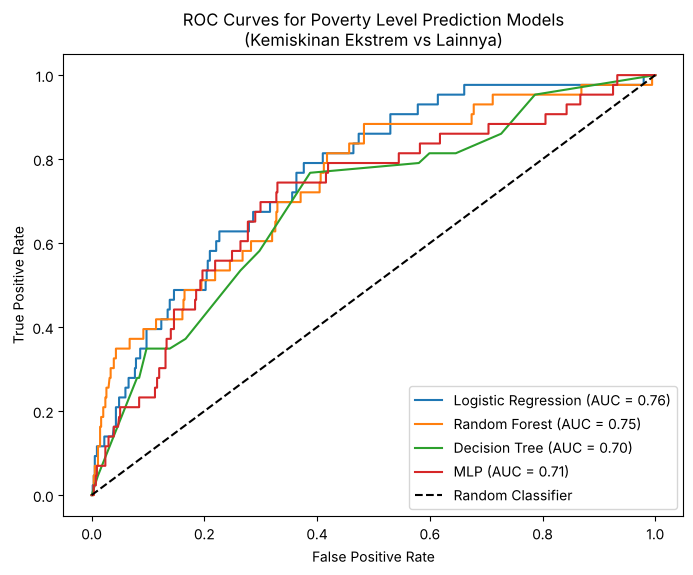

In [ ]:
# Membuat ROC Analisis
def plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp):
    plt.figure(figsize=(8, 6))

    # Hitung kurva ROC untuk setiap model
    fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_logreg)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
    fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
    fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_mlp)

    # Plot-kan kurva ROC
    plt.plot(fpr_logreg, tpr_logreg, label=f'Logistic Regression (AUC = {auc_logreg:.2f})')
    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
    plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
    plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')

    # Plot random classifier
    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

    # Format plot
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Kurva ROC untuk Poverty Level Prediction Models\n(Kemiskinan Ekstrem dengan Lainnya)')
    plt.legend()
    plt.show()

plot_roc_curves(y_test_bin, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp)

In [ ]:
def find_rates_for_thresholds(y_test, y_pred, thresholds):
    fpr_list = []
    tpr_list = []
    for threshold in thresholds:
        y_pred_binary = (y_pred > threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_binary, labels=[0, 1]).ravel()
        fpr = fp / (fp + tn)
        tpr = tp / (tp + fn)
        fpr_list.append(fpr)
        tpr_list.append(tpr)
    return fpr_list, tpr_list

thresholds = np.arange(0, 1.1, 0.1)

fpr_logreg, tpr_logreg = find_rates_for_thresholds(y_test_bin, y_pred_logreg, thresholds)
fpr_rf, tpr_rf = find_rates_for_thresholds(y_test_bin, y_pred_rf, thresholds)
fpr_dt, tpr_dt = find_rates_for_thresholds(y_test_bin, y_pred_dt, thresholds)
fpr_mlp, tpr_mlp = find_rates_for_thresholds(y_test_bin, y_pred_mlp, thresholds)

# Membuat ringkasan dalam bentuk Dataframe
summary_df = pd.DataFrame({'Threshold': thresholds.round(1),
                           'FPR LogReg': fpr_logreg, 'TPR LogReg': tpr_logreg,
                           'FPR RF': fpr_rf, 'TPR RF': tpr_rf,
                           'FPR DT': fpr_dt, 'TPR DT': tpr_dt,
                           'FPR MLP': fpr_mlp, 'TPR MLP': tpr_mlp}).round(3)

print(summary_df)

    Threshold  FPR LogReg  TPR LogReg  FPR RF  TPR RF  FPR DT  TPR DT  \
0         0.0       1.000       1.000   1.000   1.000   0.787   0.953   
1         0.1       0.685       0.977   0.788   0.953   0.727   0.860   
2         0.2       0.404       0.791   0.419   0.814   0.388   0.767   
3         0.3       0.178       0.488   0.139   0.419   0.264   0.535   
4         0.4       0.064       0.256   0.022   0.209   0.081   0.279   
5         0.5       0.004       0.023   0.002   0.000   0.011   0.047   
6         0.6       0.002       0.000   0.000   0.000   0.011   0.047   
7         0.7       0.000       0.000   0.000   0.000   0.000   0.000   
8         0.8       0.000       0.000   0.000   0.000   0.000   0.000   
9         0.9       0.000       0.000   0.000   0.000   0.000   0.000   
10        1.0       0.000       0.000   0.000   0.000   0.000   0.000   

    FPR MLP  TPR MLP  
0     1.000    1.000  
1     0.204    0.535  
2     0.110    0.233  
3     0.041    0.163  
4     0.

In [ ]:
def find_best_threshold(y_test, y_pred):
    # berdasaran Youden's Index
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    optimal_idx = np.argmax(tpr - fpr)
    return thresholds[optimal_idx]

best_threshold_logreg = find_best_threshold(y_test_bin, y_pred_logreg)
best_threshold_rf = find_best_threshold(y_test_bin, y_pred_rf)
best_threshold_dt = find_best_threshold(y_test_bin, y_pred_dt)
best_threshold_mlp = find_best_threshold(y_test_bin, y_pred_mlp)

print(f"Ambang batas terbaik untuk Logistic Regression: {best_threshold_logreg}")
print(f"Ambang batas terbaik untuk Random Forest: {best_threshold_rf}")
print(f"Ambang batas terbaik untuk Decision Tree: {best_threshold_dt}")
print(f"Ambang batas terbaik untuk MLP: {best_threshold_mlp}")

Best threshold for Logistic Regression: 0.2119840754693298
Best threshold for Random Forest: 0.18265592640112532
Best threshold for Decision Tree: 0.27368591151003496
Best threshold for MLP: 0.05529137354057344


Threshold terbaik menurut *Youden's Index* untuk mendeteksi kemiskinan ekstrem berada di kisaran rendah: Logistic Regression 0,21, Random Forest 0,18, dan Decision Tree 0,27, sedangkan MLP 0,06. Threshold standar 0,5 hampir tidak pernah tercapai karena kelas 1 hanya 7,5% dari data (pada threshold 0,5 TPR kurang dari 5% untuk semua model). Jadi jika model dipakai untuk menjaring penerima bantuan, ambang keputusan sebaiknya diturunkan ke sekitar 0,2 agar lebih banyak rumah tangga kemiskinan ekstrem terjaring, dengan konsekuensi FPR yang lebih tinggi.

**Pengingat**

1. Jika menginginkan model yang memiliki sensitivitas yang tinggi, yaitu kemampuan untuk mendeteksi sebanyak mungkin rumah tangga kemiskinan ekstrem (True Positive), maka lebih baik menggunakan ambang batas yang lebih rendah. Namun, ini mungkin juga akan menyebabkan peningkatan False Positive Rate (rumah tangga yang tidak miskin ekstrem salah diprediksi miskin ekstrem).
2. Sebaliknya, jika ingin mengurangi kesalahan memprediksi rumah tangga lain sebagai miskin ekstrem (False Positive), maka kita akan memilih ambang batas yang lebih tinggi. Namun, ini dapat mengurangi sensitivitas model (lebih banyak rumah tangga miskin ekstrem yang tidak terdeteksi).

**Kesimpulan.**

1. **Logistic Regression** dan **Random Forest** berada di posisi teratas dengan F1 macro yang praktis sama (sekitar 0,371) dan recall macro sekitar 0,40. Logistic Regression dipilih sebagai model terbaik karena AUC-ROC kelas 1 tertinggi (0,763), modelnya lebih sederhana, dan hasilnya lebih mudah dijelaskan.
2. Performa keseluruhan masih **sedang**. Model mampu menemukan sekitar 4 dari 10 rumah tangga kemiskinan ekstrem, tetapi dengan presisi rendah (sekitar 17%), artinya banyak rumah tangga lain ikut tertandai. Hal ini wajar karena hanya memakai 12 feature, kelas sangat tidak seimbang, dan batas antar level kemiskinan yang berdekatan memang sulit dibedakan.
3. Dalam uji cepat di luar notebook ini, memakai lebih banyak feature (puluhan hingga seluruh kolom) hanya menaikkan F1 macro beberapa poin, sehingga 12 feature terpilih sudah merupakan kompromi yang baik antara akurasi dan kemudahan interpretasi.
4. Jika model dipakai untuk menjaring penerima bantuan, disarankan mengunakan ambang batas yang lebih rendah (sekitar 0,2) untuk kelas kemiskinan ekstrem agar lebih banyak rumah tangga yang membutuhkan terdeteksi.

In [ ]:
import pickle

# Pilih model terbaik berdasarkan F1 macro pada data test
candidates = {'Logistic Regression': fit_clf_lg, 'Decision Tree': fit_clf_dt,
              'Random Forest': fit_clf_rf, 'MLP': fit_clf_mlp}
best_name = tuned_raw.sort_values(['F1 (macro)', 'Recall (macro)'], ascending=False).iloc[0]['Model']
print(tuned_raw[['Model', 'F1 (macro)', 'Recall (macro)']])
best_model = candidates[best_name].best_estimator_
print("Model terbaik:", best_name)

# Informasi tiap feature (dipakai untuk membuat input pada dashboard Streamlit di Capstone III)
feature_desc = {
    'escolari'    : 'Lama sekolah kepala rumah tangga (tahun)',
    'meaneduc'    : 'Rata-rata lama sekolah anggota dewasa (tahun)',
    'cielorazo'   : 'Rumah memiliki langit-langit',
    'eviv3'       : 'Kondisi lantai baik',
    'epared3'     : 'Kondisi dinding baik',
    'pisomoscer'  : 'Lantai mosaik/keramik',
    'etecho3'     : 'Kondisi atap baik',
    'hogar_nin'   : 'Jumlah anak usia 0-19 tahun',
    'overcrowding': 'Rata-rata orang per kamar',
    'v18q'        : 'Memiliki tablet',
    'rooms'       : 'Jumlah kamar',
    'edjefe'      : 'Lama sekolah kepala rumah tangga laki-laki (tahun)',
}
feature_info = {}
for col in X.columns:
    is_binary = sorted(df[col].unique().tolist()) == [0, 1]
    is_int = bool((df[col] % 1 == 0).all())
    feature_info[col] = {'desc': feature_desc[col],
                         'type': 'binary' if is_binary else ('int' if is_int else 'float'),
                         'min': float(df[col].min()), 'max': float(df[col].max()),
                         'default': float(df[col].median())}

bundle = {'model': best_model, 'model_name': best_name, 'scaler': scaler,
          'features': list(X.columns), 'feature_info': feature_info,
          'target_labels': {1: 'Kemiskinan ekstrem', 2: 'Kemiskinan moderat',
                            3: 'Rumah tangga rentan', 4: 'Rumah tangga tidak rentan'}}

# Menyimpan model terbaik dengan pickle
pklname = "generate_poverty_level.pkl"

with open(pklname, 'wb') as file:
    pickle.dump(bundle, file)

# Uji muat ulang model dan prediksi satu baris
with open(pklname, 'rb') as file:
    loaded = pickle.load(file)
contoh = loaded['scaler'].transform(X.iloc[[0]])
print("Prediksi contoh:", loaded['model'].predict(contoh)[0], "| Target sebenarnya:", y.iloc[0])

                 Model  F1 (macro)  Recall (macro)
0  Logistic Regression    0.371319        0.403793
1        Decision Tree    0.322301        0.376910
2        Random Forest    0.371257        0.406577
3                  MLP    0.351104        0.345930
Model terbaik: Logistic Regression
Prediksi contoh: 4 | Target sebenarnya: 4
